# 02 · Exploring the BTD distributions: where do the label thresholds belong?

**Goal of this notebook:** the fog labels test the brightness temperature difference
`BTD = IR_108 − IR_039` (uncorrected). The first guesses for the thresholds (for example "fog if BTD > 2.5 K")
were made before anyone had looked at real histograms. Here we look at the real data and **measure** the values.

**What we look at, in five steps**

1. BTD histograms of 12 varied scenes, each next to its Night Microphysics RGB.
2. Which hump of each histogram is clear ground and which is low cloud (judged by eye from the RGB).
3. How the level of the clear-ground hump changes with viewing angle, month and time of night.
4. How cold low-cloud tops get (`warm_min_bt108`) and how thin cirrus differs from low cloud in the
   split window `IR_108 − IR_120` (`cirrus_max_split`).
5. How often a scene has two separate humps (the idea behind the first dynamic threshold), and how the new dynamic
   threshold, clear-ground peak plus an offset, behaves on all scenes.

The BTD histograms use 0.25 K bins, so a peak position is only known to about ±0.13 K.

**Training season only.** Everything here uses the 2023-24 scenes. The 2024-25 scenes are the test set;
looking at them while choosing thresholds would leak information into the evaluation.

Run this notebook from the `notebooks/` folder. It reads the dataset path from `configs/default.yaml`.

## 0 · Setup and data

The helper functions that do the real work live in `src/fogseg/explore.py` (with tests); this notebook calls
them and draws the figures. All figures are also saved as PNG files in `docs/notes/figures/`.

In [1]:
import dataclasses
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from fogseg.config import load_config
from fogseg.dynamic_threshold import DynamicParams, clear_ground_peak, dynamic_threshold
from fogseg.explore import (
    hump_peak,
    peaks_by_group,
    pick_exploration_scenes,
    satellite_zenith_angle,
    training_scene_indices,
    valley_between,
)
from fogseg.inspect import night_microphysics_rgb
from fogseg.labels import LabelParams, histogram_pixels, local_std, trusted_mask, warm_and_not_cirrus

# fogseg.inspect switches matplotlib to a file-only backend; this brings the inline plots back.
%matplotlib inline

In [2]:
CONFIG_PATH = Path("../configs/default.yaml")
FIGURES_DIR = Path("../docs/notes/figures")
CAPTION = "Contains modified EUMETSAT Meteosat SEVIRI data (2023-24)"
FILE_DPI = 100  # the PNG files in docs/notes/figures
plt.rcParams["figure.dpi"] = 60  # the copy shown in this notebook; lower, so the notebook stays small
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEASON_MONTHS = [10, 11, 12, 1, 2]
MONTH_NAMES = ["Oct", "Nov", "Dec", "Jan", "Feb"]
BTD_BINS = np.arange(-4.0, 10.01, 0.25)


def save_figure(fig, name):
    """Add the data attribution, save the figure as PNG in docs/notes/figures and show it."""
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    fig.text(0.995, 0.004, CAPTION, ha="right", va="bottom", fontsize=7, color="0.3")
    fig.savefig(FIGURES_DIR / name, dpi=FILE_DPI, facecolor="white")
    plt.show()

In [3]:
config = load_config(CONFIG_PATH)
params = LabelParams.from_config(config["labels"])
provisional = dataclasses.replace(params, btd_fixed=2.5, warm_min_bt108=260.0, cirrus_max_split=2.0)
dataset = xr.open_zarr(config["data"]["processed_path"], consolidated=False)

all_times = pd.DatetimeIndex(dataset["time"].values)
training = training_scene_indices(all_times)
times = all_times[training]
print(f"{len(times)} training scenes, {times[0]} to {times[-1]} (of {len(all_times)} in the dataset)")

304 training scenes, 2023-10-01 21:00:00 to 2024-02-29 05:00:00 (of 608 in the dataset)


Reading the whole training season takes about a minute. We keep four channels: `IR_039` and `IR_108` for the BTD,
`IR_120` for the split window, and `IR_087` which tells ice clouds from water clouds (used in step 4).

In [4]:
training_data = dataset.isel(time=training)
channel_names = ["IR_039", "IR_087", "IR_108", "IR_120"]
brightness = training_data["bt"].sel(channel=channel_names).values
ir039, ir087, ir108, ir120 = np.moveaxis(brightness, 1, 0)
sza = training_data["sza"].values
longitude = dataset["lon"].values
latitude = dataset["lat"].values
btd = ir108 - ir039
print("brightness temperatures:", brightness.shape, brightness.dtype)

brightness temperatures: (304, 4, 241, 462) float32


**Which pixels go into a histogram.** The dynamic threshold (and every histogram below) uses the pixels
that are *night* (sun more than 95° below the horizon), have all three channels, are *warm* (`IR_108` at least
`warm_min_bt108`) and show *no thin-cirrus signature* (`IR_108 − IR_120` below `cirrus_max_split`). For now
these two thresholds are still the first guesses (260 K and 2.0 K, the variable `provisional` below) in sections 1 to 4, so
the measurements are not influenced by the values they are meant to replace. Section 5 uses the agreed values from
the config file (`params`). Step 4 measures the two thresholds.

In [5]:
in_histogram = trusted_mask(ir039, ir108, ir120, sza, params.night_min_sza) & warm_and_not_cirrus(
    ir108, ir120, provisional
)

# The labelling code builds the same histogram with `histogram_pixels`; this checks we select the same pixels.
first_scene = 0
reference = histogram_pixels(
    ir039[first_scene], ir108[first_scene], ir120[first_scene], sza[first_scene], provisional
)
assert np.array_equal(btd[first_scene][in_histogram[first_scene]], reference)
print(f"{in_histogram.mean():.0%} of all pixels are histogram pixels")

49% of all pixels are histogram pixels


## 1 · BTD histograms of 12 varied scenes

The scenes are picked by a small deterministic function (`pick_exploration_scenes`): it spreads them over
October to February and over the four night slots (21, 00, 03, 05 UTC), keeps them on different nights, and
always includes the known fog night of **21 November 2023, 00:00 UTC**. The same choice comes out every time.

Each row shows one scene:

- **Left, Night Microphysics RGB** (EUMETSAT recipe). Roughly: low water cloud and fog are pale green or
  yellowish, thick high cloud is red-brown, thin cirrus is dark red, clear ground is purple to blue.
  White lines mark 45, 50, 55 °N and 5, 10, 15, 20 °E.
- **Middle, BTD map** of the histogram pixels (grey = night pixels that were left out: cold or cirrus).
- **Right, histogram** of the BTD. Grey: all night pixels. Blue: the histogram pixels. The dashed red line is the
  provisional threshold (2.5 K), the dotted line is the clear-ground peak found automatically
  (`hump_peak`, search window 0 to 5.5 K).

In [6]:
FOGGY_SCENE = pd.Timestamp("2023-11-21 00:00")
N_EXPLORATION_SCENES = 12
CLEAR_WINDOW = (0.0, 5.5)  # K, where the clear-ground hump is searched

picked = pick_exploration_scenes(
    times, N_EXPLORATION_SCENES, config["time"]["slots"], must_include=[FOGGY_SCENE]
)
picked_positions = times.get_indexer(picked)
print(", ".join(time.strftime("%Y-%m-%d %H:%M") for time in picked))

2023-10-01 21:00, 2023-10-14 03:00, 2023-10-26 00:00, 2023-11-07 03:00, 2023-11-21 00:00, 2023-11-29 05:00, 2023-12-11 05:00, 2023-12-31 03:00, 2024-01-15 21:00, 2024-01-30 05:00, 2024-02-15 00:00, 2024-02-28 21:00


In [7]:
def draw_graticule(ax):
    """White lines of latitude and longitude, so the scene can be found on a map."""
    for field, levels, unit in ((latitude, [45, 50, 55], "°N"), (longitude, [5, 10, 15, 20], "°E")):
        lines = ax.contour(field, levels=levels, colors="white", linewidths=0.6)
        ax.clabel(lines, fmt=lambda value, unit=unit: f"{value:.0f}{unit}", fontsize=6)


def draw_scene_row(axes, scene):
    """RGB, BTD map and BTD histogram of the scene at position `scene` of the training scenes."""
    rgb_ax, map_ax, histogram_ax = axes
    scene_btd = btd[scene]
    histogram_btd = scene_btd[in_histogram[scene]]
    is_night = sza[scene] > params.night_min_sza

    rgb_ax.imshow(night_microphysics_rgb(ir039[scene], ir108[scene], ir120[scene]))
    rgb_ax.set_title(f"{times[scene]:%Y-%m-%d %H:%M} UTC, Night Microphysics RGB", fontsize=10)

    map_ax.set_facecolor("0.8")
    btd_map = map_ax.imshow(np.where(in_histogram[scene], scene_btd, np.nan), cmap="viridis", vmin=-2, vmax=8)
    map_ax.figure.colorbar(btd_map, ax=map_ax, shrink=0.85, label="BTD (K)")
    map_ax.set_title("BTD of the histogram pixels", fontsize=10)
    for ax in (rgb_ax, map_ax):
        draw_graticule(ax)
        ax.set_xticks([])
        ax.set_yticks([])

    histogram_ax.hist(scene_btd[is_night], bins=BTD_BINS, color="0.8", label="all night pixels")
    histogram_ax.hist(histogram_btd, bins=BTD_BINS, color="tab:blue", label="histogram pixels")
    histogram_ax.axvline(provisional.btd_fixed, color="red", linestyle="--", label="provisional 2.5 K")
    clear_peak = hump_peak(histogram_btd, CLEAR_WINDOW)
    if np.isfinite(clear_peak):
        histogram_ax.axvline(clear_peak, color="black", linestyle=":", label=f"clear peak {clear_peak:.2f} K")
    histogram_ax.set_xlim(BTD_BINS[0], BTD_BINS[-1])
    histogram_ax.set_xlabel("IR_108 − IR_039 (K)")
    histogram_ax.set_ylabel("pixels per 0.25 K")
    histogram_ax.set_title("BTD histogram", fontsize=10)
    histogram_ax.legend(fontsize=7)


def scene_overview(positions, name):
    fig, rows = plt.subplots(
        len(positions), 3, figsize=(15, 3.1 * len(positions)), gridspec_kw={"width_ratios": [1.3, 1.3, 1]}
    )
    for axes, scene in zip(rows, positions):
        draw_scene_row(axes, scene)
    save_figure(fig, name)

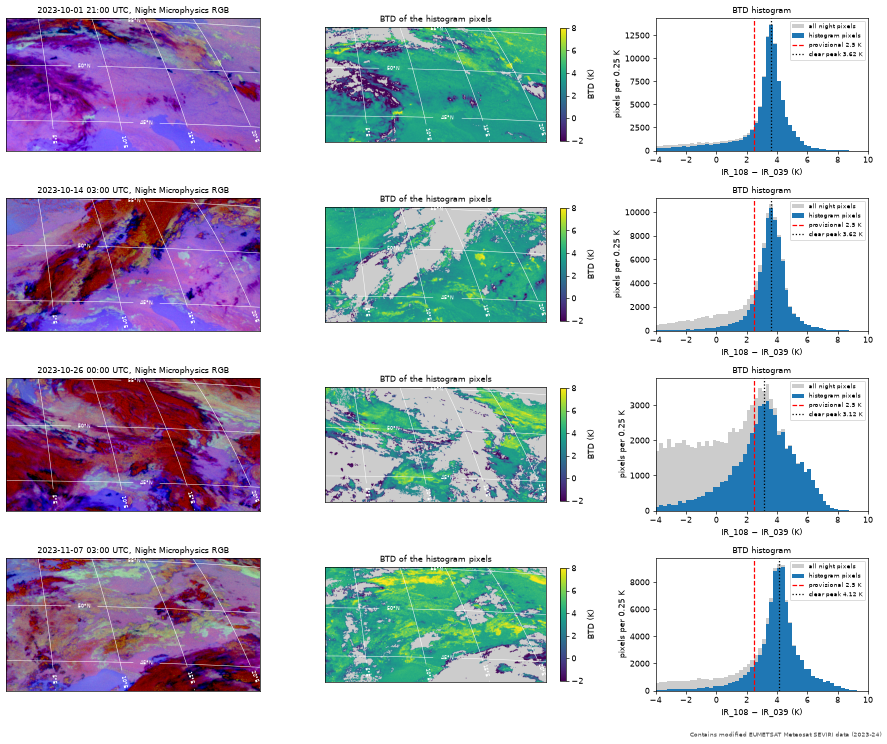

In [8]:
scene_overview(picked_positions[:4], "scene_overview_1.png")

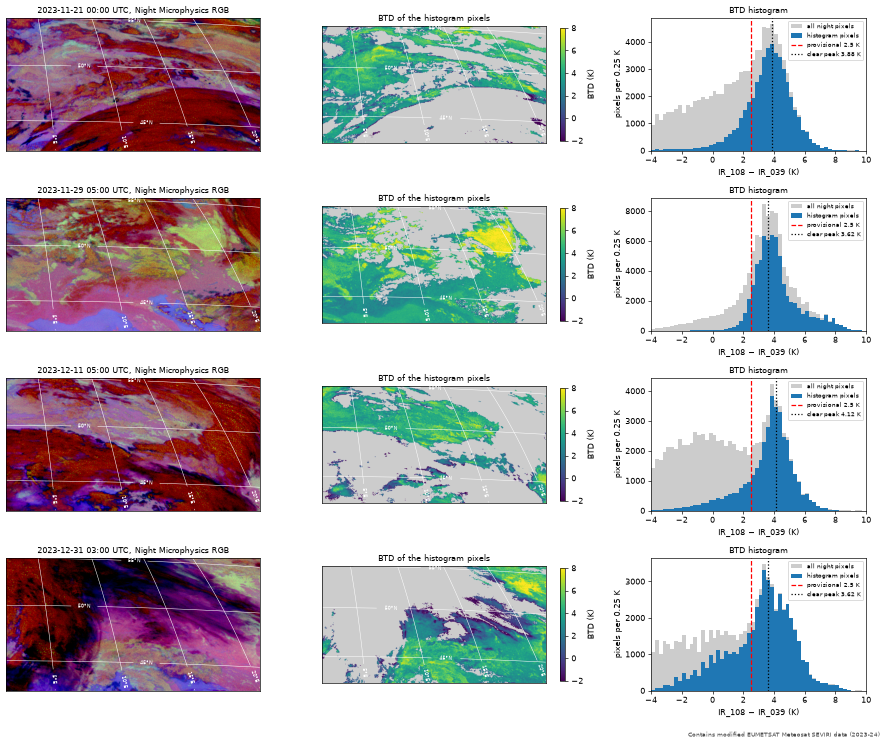

In [9]:
scene_overview(picked_positions[4:8], "scene_overview_2.png")

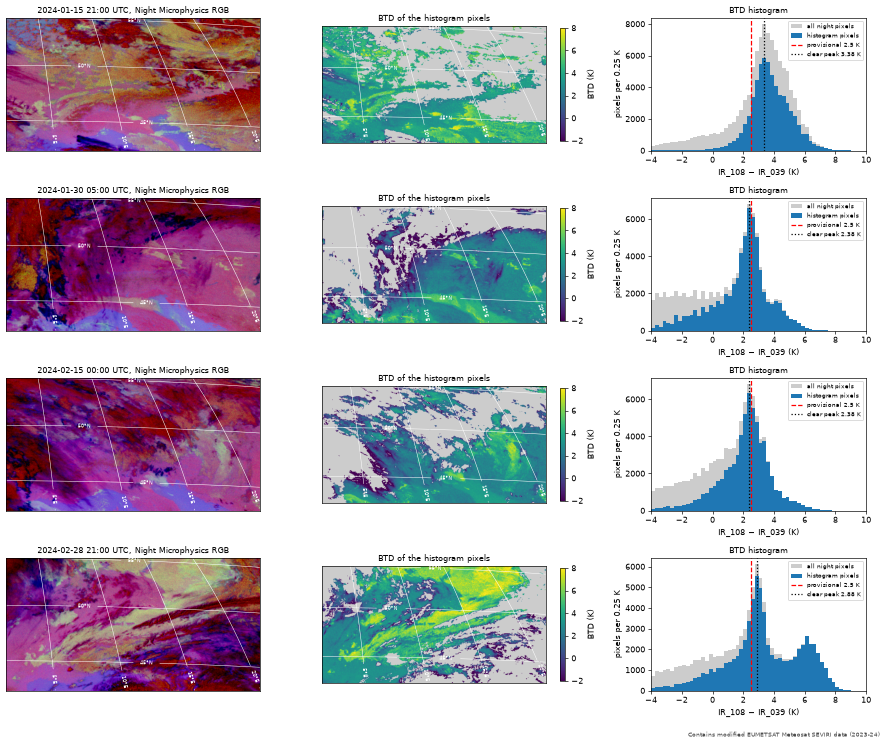

In [10]:
scene_overview(picked_positions[8:], "scene_overview_3.png")

## 2 · Which hump is clear ground, which is low cloud?

I looked at the RGB and the BTD map of every scene in section 1 and decided by colour and shape: in the RGB, clear
ground is purple, pink or blue, and low cloud or fog is pale green to yellowish with a smooth texture. The BTD of these
pixels is then read from the BTD map and the histogram next to them. The values are read to about 0.25 K for the
clear-ground peak and about 0.5 K for the low cloud, which is often not a hump of its own but a shoulder or a tail.

| Scene (UTC) | Clear-ground peak | Low-cloud level | Remarks |
|---|---|---|---|
| 2023-10-01 21:00 | 3.6 K | none (patches at 5 to 7 K) | Almost clear and warm. One sharp hump; a few small pale-green patches give a thin tail. |
| 2023-10-14 03:00 | 3.6 K | none (patches at 5 to 6 K) | High cloud bands are left out by the cirrus and warm tests; the rest is clear. |
| 2023-10-26 00:00 | 3.1 K | about 5.5 K, shoulder | **Ambiguous.** Broken high cloud everywhere, so the hump is broad (2 to 4.5 K) and mixed pixels blur it. |
| 2023-11-07 03:00 | 4.1 K | about 6 K, shoulder | Clear ground in the south and centre, pale-green low cloud in the north: a shoulder, not a second hump. |
| 2023-11-21 00:00 | 3.9 K | about 5 K, merged | **Ambiguous (the fog night).** The pale lilac decks over France and the Benelux have a BTD of 4 to 5.5 K, only a little above the ground; no separate hump. |
| 2023-11-29 05:00 | 3.6 K | about 7.5 K, broad | Large pale-green low-cloud deck in the north-east: a long tail up to 9 K, with the clear hump in the south. |
| 2023-12-11 05:00 | 4.1 K | none | **Ambiguous.** Mostly high cloud. The pixels that remain are a pale lilac band in the north that may be thin low or mid cloud rather than ground. |
| 2023-12-31 03:00 | 3.6 K | about 5.5 K, shoulder | Fog or stratus in the Po Valley (pale yellow in the RGB) at 5 to 6.5 K. |
| 2024-01-15 21:00 | 3.4 K | about 5.5 K, shoulder | Patches of low cloud south of the Alps and in the centre. |
| 2024-01-30 05:00 | 2.4 K | none | Cold clear night: one sharp hump at **2.4 K**. The provisional 2.5 K threshold lies right on its peak. |
| 2024-02-15 00:00 | 2.4 K | about 5.5 K, small patches | Same cold regime: clear ground at **2.4 K**, a few small low-cloud patches. |
| 2024-02-28 21:00 | 2.9 K | 6.2 K, own hump | The clearest two-hump case: clear ground at 2.9 K, a low-cloud deck at 6.2 K, valley near 4.0 K. |

**What the table says**

- The clear-ground hump is the one big hump in every scene, between **2.4 K and 4.1 K**. It is *not* at 0 K and not
  always at 2 K: it moves with the weather (cold, dry nights in January and February are the lowest).
- Low cloud sits clearly above the ground, at about **5 to 8 K**, but it is almost never a separate hump. It is a
  shoulder or a tail, because low cloud covers only part of a scene and its BTD varies from deck to deck.
- Only one of the 12 scenes (28 February) has two real humps. Section 5 counts this for all 304 scenes.
- Three scenes (26 October, 21 November, 11 December) are ambiguous: where cloud covers most of the region, a
  broad hump of cloud can pass for the ground. Section 3 therefore also checks that the clear-ground level does not
  change when mostly cloud-free scenes are looked at alone.
- The provisional threshold of 2.5 K sits *on the clear-ground peak* in the two cold scenes and 0.6 to 1.6 K below
  it in the others. Used as it is, it would label clear ground as fog.

## 3 · Does the clear-ground level drift with viewing angle, month or time of night?

If clear ground always sat at the same BTD, one fixed threshold would do. If it moves, a fixed threshold is
too low in some places and too high in others.

**How clear ground is isolated.** There is no cloud mask in the dataset, so we use the histogram itself.
For every scene we take the histogram pixels (night, warm, no cirrus signature) and find the highest peak of the
smoothed histogram between 0 and 5.5 K (`hump_peak`). Why this is a fair estimate of the clear-ground level:

- Section 2 shows that the clear-ground hump of every judged scene lies inside this window (2.4 to 4.1 K), and that the
  low cloud lies mostly above it, so it cannot pull the peak away.
- The peak (the mode) is used, not the mean: a low-cloud shoulder moves the mean but barely moves the mode.
- If the highest bin sits on the edge of the window, the hump is not inside the window (for example a scene
  covered by a low-cloud deck at 6 to 8 K) and the scene gets no value instead of a wrong one.
- Scenes or bins with fewer than 1000 histogram pixels get no value either.

The weak spot is a scene where cloud covers most of the region and its hump is higher than the clear one inside the
window; the peak then follows the cloud (21 November and 11 December may be like this). The check after the figure
repeats the measurement for scenes grouped by how cloud-free they are.

**Viewing angle.** `satellite_zenith_angle` computes the angle between the vertical and the line to the satellite
for every pixel. Our region spans about 49° to 68°. We cut it into 10 equal bins and find the clear-ground peak
in each bin of each scene. Comparing a bin with the *same scene's* whole-region peak removes the weather
(a cold air mass moves the whole scene up or down), so only the effect of the viewing angle remains.

In [11]:
N_ZENITH_BINS = 10
zenith = satellite_zenith_angle(longitude, latitude).astype(float)
zenith_edges = np.linspace(zenith.min(), zenith.max(), N_ZENITH_BINS + 1)
zenith_centres = (zenith_edges[:-1] + zenith_edges[1:]) / 2
zenith_bin = np.digitize(zenith, zenith_edges[1:-1])
print(f"viewing zenith angle: {zenith.min():.1f} to {zenith.max():.1f} degrees")
print(
    f"correlation of the viewing angle with latitude: {np.corrcoef(zenith.ravel(), latitude.ravel())[0, 1]:.2f}"
)

viewing zenith angle: 49.2 to 68.4 degrees
correlation of the viewing angle with latitude: 0.96


In [12]:
scene_peak = np.full(len(times), np.nan)
peak_by_zenith_bin = np.full((len(times), N_ZENITH_BINS), np.nan)

for scene in range(len(times)):
    histogram_btd = btd[scene][in_histogram[scene]]
    bins_of_pixels = zenith_bin[in_histogram[scene]]
    scene_peak[scene] = hump_peak(histogram_btd, CLEAR_WINDOW)
    peak_by_zenith_bin[scene] = peaks_by_group(histogram_btd, bins_of_pixels, N_ZENITH_BINS, CLEAR_WINDOW)

scene_peaks = pd.DataFrame(
    {"time": times, "month": times.month, "slot": times.strftime("%H:%M"), "clear_peak": scene_peak}
)
print(f"{np.isfinite(scene_peak).sum()} of {len(times)} scenes have a clear-ground peak")
print(scene_peaks["clear_peak"].describe().round(2).to_string())
print(
    "percentiles 1, 5, 50, 95, 99:",
    scene_peaks["clear_peak"].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(2).tolist(),
)
print(
    "lowest peaks:",
    ", ".join(
        f"{t:%Y-%m-%d %H:%M} ({p:.2f} K)"
        for t, p in scene_peaks.nsmallest(5, "clear_peak")[["time", "clear_peak"]].itertuples(index=False)
    ),
)

303 of 304 scenes have a clear-ground peak
count    303.00
mean       3.53
std        0.57
min        1.88
25%        3.12
50%        3.62
75%        3.88
max        5.12
percentiles 1, 5, 50, 95, 99: [1.88, 2.4, 3.62, 4.38, 4.62]
lowest peaks: 2024-01-22 00:00 (1.88 K), 2024-01-22 03:00 (1.88 K), 2024-01-22 05:00 (1.88 K), 2024-02-05 00:00 (1.88 K), 2023-10-06 05:00 (2.12 K)


In [13]:
MIN_SCENES_PER_BIN = 100
slots = config["time"]["slots"]

scenes_per_bin = np.isfinite(peak_by_zenith_bin).sum(axis=0)
enough_scenes = scenes_per_bin >= MIN_SCENES_PER_BIN
relative_peak = peak_by_zenith_bin - scene_peak[:, None]


def over_scenes(values, percentile):
    """Percentile over the scenes for each zenith bin; NaN for bins with too few scenes."""
    result = np.full(N_ZENITH_BINS, np.nan)
    result[enough_scenes] = np.nanpercentile(values[:, enough_scenes], percentile, axis=0)
    return result


zenith_table = pd.DataFrame(
    {
        "zenith centre (deg)": zenith_centres.round(1),
        "pixel share": (np.bincount(zenith_bin.ravel(), minlength=N_ZENITH_BINS) / zenith_bin.size).round(3),
        "scenes with a peak": scenes_per_bin,
        "median peak (K)": over_scenes(peak_by_zenith_bin, 50).round(2),
        "median vs scene peak (K)": over_scenes(relative_peak, 50).round(2),
    }
)
print(zenith_table.to_string(index=False))

bin_index = np.broadcast_to(zenith_centres, relative_peak.shape)
usable = np.isfinite(relative_peak) & enough_scenes[None, :]
slope_per_degree, intercept = np.polyfit(bin_index[usable], relative_peak[usable], 1)
usable_span = zenith_centres[enough_scenes].max() - zenith_centres[enough_scenes].min()
print(f"\nStraight-line fit through all scene-bin values: {slope_per_degree:+.3f} K per degree,")
print(
    f"that is {slope_per_degree * usable_span:+.2f} K over the {usable_span:.0f} degrees with enough scenes"
)

 zenith centre (deg)  pixel share  scenes with a peak  median peak (K)  median vs scene peak (K)
                50.1        0.066                 271             3.62                      0.00
                52.1        0.125                 292             3.38                     -0.25
                54.0        0.151                 286             3.12                     -0.25
                55.9        0.145                 292             3.38                      0.00
                57.8        0.138                 278             3.62                      0.00
                59.8        0.130                 267             3.88                      0.25
                61.7        0.123                 263             4.12                      0.25
                63.6        0.078                 216             4.38                      0.50
                65.5        0.034                 108             4.38                      0.75
                67.5        0.

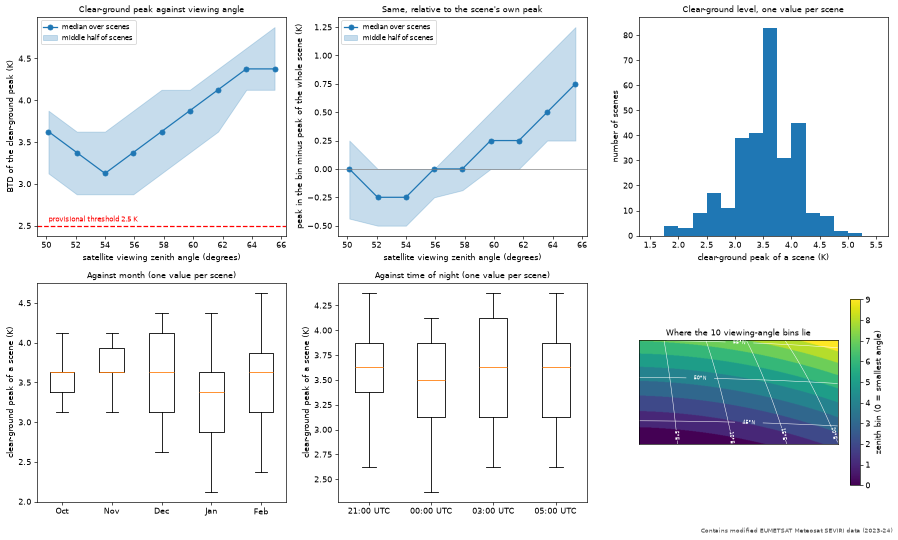

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
(zenith_ax, relative_ax, spread_ax), (month_ax, slot_ax, bins_ax) = axes

for ax, values, title in (
    (zenith_ax, peak_by_zenith_bin, "Clear-ground peak against viewing angle"),
    (relative_ax, relative_peak, "Same, relative to the scene's own peak"),
):
    ax.plot(zenith_centres, over_scenes(values, 50), "o-", color="tab:blue", label="median over scenes")
    ax.fill_between(
        zenith_centres,
        over_scenes(values, 25),
        over_scenes(values, 75),
        color="tab:blue",
        alpha=0.25,
        label="middle half of scenes",
    )
    ax.set_xlabel("satellite viewing zenith angle (degrees)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
zenith_ax.set_ylabel("BTD of the clear-ground peak (K)")
zenith_ax.axhline(provisional.btd_fixed, color="red", linestyle="--")
zenith_ax.text(
    zenith_centres[0], provisional.btd_fixed + 0.05, "provisional threshold 2.5 K", color="red", fontsize=8
)
relative_ax.set_ylabel("peak in the bin minus peak of the whole scene (K)")
relative_ax.axhline(0, color="0.5", linewidth=0.8)

spread_ax.hist(scene_peak[np.isfinite(scene_peak)], bins=np.arange(1.5, 5.51, 0.25), color="tab:blue")
spread_ax.set_xlabel("clear-ground peak of a scene (K)")
spread_ax.set_ylabel("number of scenes")
spread_ax.set_title("Clear-ground level, one value per scene", fontsize=10)

for ax, groups, labels, title in (
    (
        month_ax,
        [scene_peaks.loc[scene_peaks["month"] == m, "clear_peak"].dropna() for m in SEASON_MONTHS],
        MONTH_NAMES,
        "Against month",
    ),
    (
        slot_ax,
        [scene_peaks.loc[scene_peaks["slot"] == s, "clear_peak"].dropna() for s in slots],
        [f"{s} UTC" for s in slots],
        "Against time of night",
    ),
):
    ax.boxplot(groups, whis=(5, 95), showfliers=False)
    ax.set_xticks(range(1, len(labels) + 1), labels)
    ax.set_ylabel("clear-ground peak of a scene (K)")
    ax.set_title(f"{title} (one value per scene)", fontsize=10)

zenith_map = bins_ax.imshow(zenith_bin, cmap="viridis")
bins_ax.figure.colorbar(zenith_map, ax=bins_ax, shrink=0.85, label="zenith bin (0 = smallest angle)")
bins_ax.set_xticks([])
bins_ax.set_yticks([])
draw_graticule(bins_ax)
bins_ax.set_title("Where the 10 viewing-angle bins lie", fontsize=10)
save_figure(fig, "clear_ground_drift.png")

In [15]:
def summarise_peaks(group):
    """Number of scenes and the median and middle half of the clear-ground peak, per group."""
    grouped = scene_peaks.groupby(group, observed=True)["clear_peak"]
    return pd.DataFrame(
        {
            "scenes": grouped.count(),
            "median (K)": grouped.median(),
            "q25 (K)": grouped.quantile(0.25),
            "q75 (K)": grouped.quantile(0.75),
        }
    )


print(summarise_peaks("month").loc[SEASON_MONTHS].round(2).to_string(), "\n")
print(summarise_peaks("slot").loc[slots].round(2).to_string())

       scenes  median (K)  q25 (K)  q75 (K)
month                                      
10         61        3.62     3.38     3.62
11         60        3.62     3.62     3.94
12         63        3.62     3.12     4.12
1          61        3.38     2.88     3.62
2          58        3.62     3.12     3.88 

       scenes  median (K)  q25 (K)  q75 (K)
slot                                       
21:00      75        3.62     3.38     3.88
00:00      76        3.50     3.12     3.88
03:00      76        3.62     3.12     4.12
05:00      76        3.62     3.12     3.88


**Is the clear-ground level an artefact of cloud?** In a scene covered by cloud, a broad cloud hump could be
mistaken for the ground. The test below groups the scenes by the share of their night pixels that are histogram
pixels: a high share means few cold or cirrus-covered pixels, so a mostly cloud-free scene. If the clear-ground peak
were really a cloud hump, it would change with this share.

In [16]:
night_pixels = trusted_mask(ir039, ir108, ir120, sza, params.night_min_sza).sum(axis=(1, 2))
scene_peaks["histogram_share"] = in_histogram.sum(axis=(1, 2)) / night_pixels
scene_peaks["share_group"] = pd.cut(scene_peaks["histogram_share"], [0, 0.4, 0.6, 0.8, 1.0])
print("Clear-ground peak by share of night pixels that are histogram pixels:")
print(summarise_peaks("share_group").round(2).to_string())

Clear-ground peak by share of night pixels that are histogram pixels:
             scenes  median (K)  q25 (K)  q75 (K)
share_group                                      
(0.0, 0.4]       81        3.62     3.38     4.12
(0.4, 0.6]      127        3.62     3.12     3.75
(0.6, 0.8]       77        3.38     2.88     3.88
(0.8, 1.0]       18        3.62     3.12     4.06


**What section 3 shows**

- **The level of clear ground is far from 0 K, and it varies from scene to scene**: the median is 3.6 K, the middle
  half of the scenes lies between 3.1 and 3.9 K, and a few cold nights are as low as 1.9 K (22 January, 5 February).
  One fixed threshold cannot sit right for all of them.
- **Viewing angle matters most.** In the cleanest part of the region the clear-ground peak rises by about
  1 K between 54° and 65° (about +0.06 K per degree). In the south, below 54°, it is higher again (sea and
  land mix there), so the drift is not a perfect straight line, and the viewing angle is tied to latitude
  (correlation 0.96), so surface type and air temperature are mixed in with it.
- **Month and time of night matter little**: the medians differ by 0.1 to 0.25 K between months and slots, far less than
  the 0.6 K spread between scenes of the same month. January is the lowest month.
- The clear-ground level is the same (3.4 to 3.6 K) for mostly cloud-free and for cloudy scenes, so it is not a cloud
  hump in disguise.

## 4 · Warm tops and thin cirrus

Two thresholds of the labelling rule are tested here. To avoid circular reasoning, **no population below is
chosen with the threshold it is used to measure.**

**`warm_min_bt108`: how cold can a low-cloud top be?** A pixel must be at least this warm to count as low cloud.
Too high and cold-season fog is thrown away; too low and mid-level cloud gets in. We take pixels that are low
water cloud by three tests that do not involve `IR_108` temperature:

- night, all channels valid, and a smooth `IR_108` top (local standard deviation under 1.5 K, as in the labelling rule),
- **high BTD**, at least 5.5 K (above the clear-ground humps of section 3: 99 % of the scene peaks are at 4.6 K or lower),
- **no ice signature**: `IR_087 − IR_108` below 0 K. Ice clouds absorb more at 8.7 µm than at 10.8 µm, so they have
  a positive difference; water cloud and ground do not (Strabala et al. 1994).

Caveat: BTD shrinks a little for colder surfaces, so asking for a high BTD slightly under-counts the very coldest
low cloud. We test the BTD limit 5.0, 5.5 and 6.0 K below; if the result barely moves, the caveat is small.

**`cirrus_max_split`: how big may `IR_108 − IR_120` be for low cloud?** Thin cirrus lets ground radiation through
and has a large split; water cloud has a small one. We compare two populations:

- **low cloud**: the pixels above,
- **thin cirrus**: night pixels with the ice signature (`IR_087 − IR_108` of at least +1 K) that are still
  warmer than 250 K. A thick ice cloud top is colder than that; a warm pixel with an ice signature is
  semi-transparent ice over warm ground. This population does not use the split-window difference.

In [17]:
LOW_CLOUD_MIN_BTD = 5.5  # K
WATER_CLOUD_MAX_ICE_SIGNAL = 0.0  # K, IR_087 - IR_108
THIN_CIRRUS_MIN_ICE_SIGNAL = 1.0  # K
THIN_CIRRUS_MIN_BT108 = 250.0  # K

is_smooth = np.stack([local_std(ir108[scene]) for scene in range(len(times))]) < params.smooth_max_std
night_valid = trusted_mask(ir039, ir108, ir120, sza, params.night_min_sza) & np.isfinite(ir087)
ice_signal = ir087 - ir108
split = ir108 - ir120
scene_month = np.broadcast_to(times.month.values[:, None, None], ir108.shape)


def low_cloud_mask(min_btd):
    return night_valid & is_smooth & (btd >= min_btd) & (ice_signal < WATER_CLOUD_MAX_ICE_SIGNAL)


low_cloud = low_cloud_mask(LOW_CLOUD_MIN_BTD)
thin_cirrus = night_valid & (ice_signal >= THIN_CIRRUS_MIN_ICE_SIGNAL) & (ir108 >= THIN_CIRRUS_MIN_BT108)
print(f"low-cloud pixels: {low_cloud.sum():,}, thin-cirrus pixels: {thin_cirrus.sum():,}")

low-cloud pixels: 1,752,470, thin-cirrus pixels: 321,986


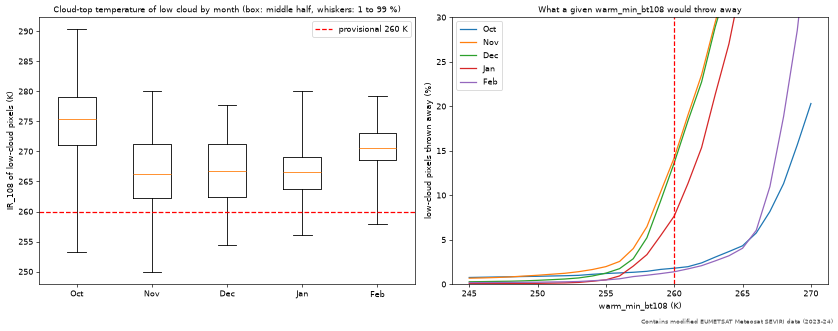

In [18]:
CANDIDATE_TEMPERATURES = np.arange(245.0, 270.1, 1.0)
low_cloud_by_month = [ir108[low_cloud & (scene_month == month)] for month in SEASON_MONTHS]

fig, (box_ax, cut_ax) = plt.subplots(1, 2, figsize=(14, 5.5))
box_ax.boxplot(low_cloud_by_month, whis=(1, 99), showfliers=False)
box_ax.set_xticks(range(1, len(MONTH_NAMES) + 1), MONTH_NAMES)
box_ax.axhline(provisional.warm_min_bt108, color="red", linestyle="--", label="provisional 260 K")
box_ax.set_ylabel("IR_108 of low-cloud pixels (K)")
box_ax.set_title(
    "Cloud-top temperature of low cloud by month (box: middle half, whiskers: 1 to 99 %)", fontsize=10
)
box_ax.legend()

for month_name, values in zip(MONTH_NAMES, low_cloud_by_month):
    colder_share = [(values < temperature).mean() for temperature in CANDIDATE_TEMPERATURES]
    cut_ax.plot(CANDIDATE_TEMPERATURES, np.array(colder_share) * 100, label=month_name)
cut_ax.axvline(provisional.warm_min_bt108, color="red", linestyle="--")
cut_ax.set_xlabel("warm_min_bt108 (K)")
cut_ax.set_ylabel("low-cloud pixels thrown away (%)")
cut_ax.set_title("What a given warm_min_bt108 would throw away", fontsize=10)
cut_ax.set_ylim(0, 30)
cut_ax.legend()
save_figure(fig, "low_cloud_top_temperature.png")

In [19]:
rows = []
for min_btd in (5.0, 5.5, 6.0):
    population = low_cloud_mask(min_btd)
    for month, month_name in zip(SEASON_MONTHS, MONTH_NAMES):
        values = ir108[population & (scene_month == month)]
        rows.append(
            {
                "BTD at least (K)": min_btd,
                "month": month_name,
                "pixels": values.size,
                "1st percentile (K)": round(float(np.percentile(values, 1)), 1),
                "5th percentile (K)": round(float(np.percentile(values, 5)), 1),
                "colder than 255 K (%)": round((values < 255).mean() * 100, 1),
                "colder than 260 K (%)": round((values < 260).mean() * 100, 1),
            }
        )
print(pd.DataFrame(rows).to_string(index=False))

 BTD at least (K) month  pixels  1st percentile (K)  5th percentile (K)  colder than 255 K (%)  colder than 260 K (%)
              5.0   Oct  272928               253.6               264.4                    1.3                    2.3
              5.0   Nov  553405               249.1               257.3                    2.3                   13.8
              5.0   Dec  614379               253.2               257.5                    1.7                   15.1
              5.0   Jan  646501               255.4               258.2                    0.8                    9.3
              5.0   Feb  535248               256.5               264.2                    0.6                    2.0
              5.5   Oct  169366               253.2               265.6                    1.2                    1.8
              5.5   Nov  364434               249.9               257.5                    2.0                   14.2
              5.5   Dec  413030               254.4     

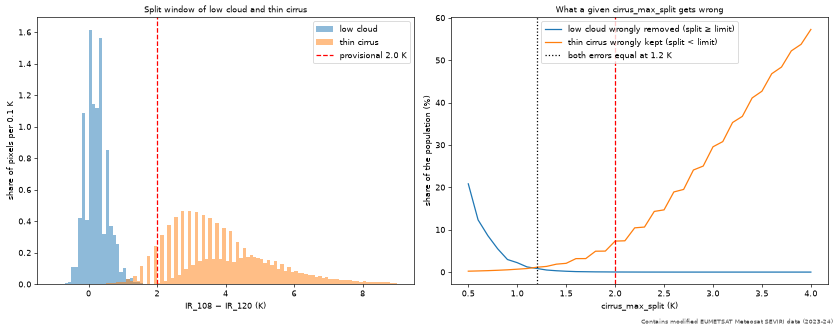

split percentiles 5, 25, 50, 75, 95, 99
low cloud : [-0.28  0.02  0.2   0.37  0.83  1.16]
thin cirrus: [1.15 1.91 2.9  3.75 4.89 7.15] (1, 5, 25, 50, 75, 95)
limit 1.0 K: low cloud removed 2.2%, thin cirrus kept 0.7%
limit 1.5 K: low cloud removed 0.2%, thin cirrus kept 2.1%
limit 2.0 K: low cloud removed 0.0%, thin cirrus kept 7.3%


In [20]:
SPLIT_BINS = np.arange(-1.0, 9.01, 0.1)
CANDIDATE_SPLITS = np.arange(0.5, 4.01, 0.1)
low_cloud_split = split[low_cloud]
thin_cirrus_split = split[thin_cirrus]

low_cloud_cut_off = np.array([(low_cloud_split >= limit).mean() for limit in CANDIDATE_SPLITS])
cirrus_let_through = np.array([(thin_cirrus_split < limit).mean() for limit in CANDIDATE_SPLITS])
equal_error = CANDIDATE_SPLITS[np.argmin(np.abs(low_cloud_cut_off - cirrus_let_through))]

fig, (density_ax, error_ax) = plt.subplots(1, 2, figsize=(14, 5.5))
density_ax.hist(
    low_cloud_split, bins=SPLIT_BINS, density=True, histtype="stepfilled", alpha=0.5, label="low cloud"
)
density_ax.hist(
    thin_cirrus_split, bins=SPLIT_BINS, density=True, histtype="stepfilled", alpha=0.5, label="thin cirrus"
)
density_ax.axvline(provisional.cirrus_max_split, color="red", linestyle="--", label="provisional 2.0 K")
density_ax.set_xlabel("IR_108 − IR_120 (K)")
density_ax.set_ylabel("share of pixels per 0.1 K")
density_ax.set_title("Split window of low cloud and thin cirrus", fontsize=10)
density_ax.legend()

error_ax.plot(CANDIDATE_SPLITS, low_cloud_cut_off * 100, label="low cloud wrongly removed (split ≥ limit)")
error_ax.plot(CANDIDATE_SPLITS, cirrus_let_through * 100, label="thin cirrus wrongly kept (split < limit)")
error_ax.axvline(provisional.cirrus_max_split, color="red", linestyle="--")
error_ax.axvline(equal_error, color="black", linestyle=":", label=f"both errors equal at {equal_error:.1f} K")
error_ax.set_xlabel("cirrus_max_split (K)")
error_ax.set_ylabel("share of the population (%)")
error_ax.set_title("What a given cirrus_max_split gets wrong", fontsize=10)
error_ax.legend()
save_figure(fig, "cirrus_split_window.png")

print("split percentiles 5, 25, 50, 75, 95, 99")
print("low cloud :", np.percentile(low_cloud_split, [5, 25, 50, 75, 95, 99]).round(2))
print(
    "thin cirrus:",
    np.percentile(thin_cirrus_split, [1, 5, 25, 50, 75, 95]).round(2),
    "(1, 5, 25, 50, 75, 95)",
)
for limit in (1.0, 1.5, 2.0):
    index = np.argmin(np.abs(CANDIDATE_SPLITS - limit))
    print(
        f"limit {limit} K: low cloud removed {low_cloud_cut_off[index]:.1%}, thin cirrus kept {cirrus_let_through[index]:.1%}"
    )

## 5 · Two humps, or one hump and an offset? The dynamic threshold

The first design of the dynamic threshold looked for a valley between a clear-ground hump and a low-cloud hump.
Section 2 suggests that real scenes rarely have the second hump. Here we count it over all 304 scenes:

- the clear-ground peak is the one of section 3;
- the low-cloud peak is the highest peak of the histogram at least 1.5 K *above* the clear-ground peak
  (`hump_peak`, which rejects a tail that only falls off from the left edge of its window);
- the valley is the lowest point between the two (`valley_between`), and its *depth* is its height divided by the
  height of the smaller peak: 0 for two separate humps, 1 for no valley at all.

In [21]:
CLOUD_PEAK_MIN_GAP = 1.5  # K above the clear-ground peak
CLOUD_PEAK_SEARCH_END = 10.0  # K

two_hump_rows = []
for scene in range(len(times)):
    clear_peak = scene_peak[scene]
    if not np.isfinite(clear_peak):
        continue
    histogram_btd = btd[scene][in_histogram[scene]]
    cloud_peak = hump_peak(histogram_btd, (clear_peak + CLOUD_PEAK_MIN_GAP, CLOUD_PEAK_SEARCH_END))
    if not np.isfinite(cloud_peak):
        continue
    valley_btd, valley_depth = valley_between(histogram_btd, clear_peak, cloud_peak)
    two_hump_rows.append(
        {
            "time": times[scene],
            "clear_peak": clear_peak,
            "cloud_peak": cloud_peak,
            "valley": valley_btd,
            "cloud_above_clear": cloud_peak - clear_peak,
            "valley_above_clear": valley_btd - clear_peak,
            "depth": valley_depth,
        }
    )
two_humps = pd.DataFrame(two_hump_rows)

n_with_clear_peak = int(np.isfinite(scene_peak).sum())
print(
    f"{len(two_humps)} of {n_with_clear_peak} scenes have a second peak at least {CLOUD_PEAK_MIN_GAP} K above the clear peak"
)
print(two_humps.drop(columns="time").describe().round(2).to_string())
print(f"valley depth at most 0.5 (the provisional limit): {(two_humps['depth'] <= 0.5).sum()} scenes")
print("months of the two-hump scenes:", two_humps["time"].dt.month.value_counts().sort_index().to_dict())

41 of 303 scenes have a second peak at least 1.5 K above the clear peak
       clear_peak  cloud_peak  valley  cloud_above_clear  valley_above_clear  depth
count       41.00       41.00   41.00              41.00               41.00  41.00
mean         3.12        5.78    4.66               2.66                1.54   0.79
std          0.71        1.03    0.80               0.53                0.32   0.15
min          1.88        3.99    3.12               1.86                1.00   0.46
25%          2.62        5.23    3.88               2.14                1.50   0.70
50%          3.12        5.72    4.62               2.60                1.50   0.78
75%          3.62        6.29    5.38               3.09                1.75   0.91
max          4.38        7.93    6.12               3.81                2.25   1.02
valley depth at most 0.5 (the provisional limit): 1 scenes
months of the two-hump scenes: {1: 14, 2: 18, 10: 2, 11: 3, 12: 4}


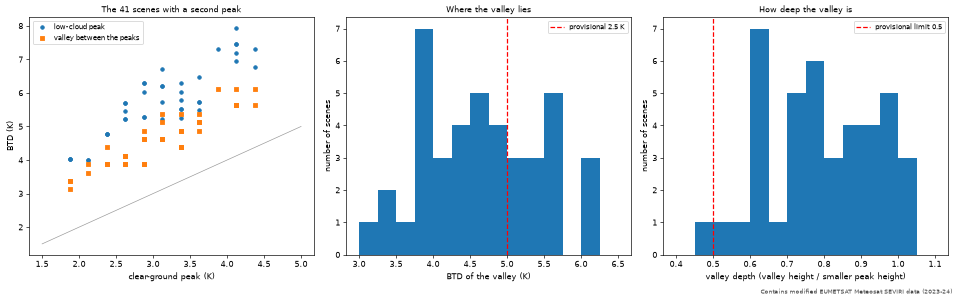

In [22]:
fig, (scatter_ax, valley_ax, depth_ax) = plt.subplots(1, 3, figsize=(16, 5))

scatter_ax.scatter(two_humps["clear_peak"], two_humps["cloud_peak"], s=18, label="low-cloud peak")
scatter_ax.scatter(
    two_humps["clear_peak"], two_humps["valley"], s=18, marker="s", label="valley between the peaks"
)
scatter_ax.plot([1.5, 5], [1.5, 5], color="0.6", linewidth=0.8)
scatter_ax.set_xlabel("clear-ground peak (K)")
scatter_ax.set_ylabel("BTD (K)")
scatter_ax.set_title(f"The {len(two_humps)} scenes with a second peak", fontsize=10)
scatter_ax.legend(fontsize=8)

valley_ax.hist(two_humps["valley"], bins=np.arange(3.0, 6.51, 0.25), color="tab:blue")
valley_ax.axvline(params.btd_fixed, color="red", linestyle="--", label="provisional 2.5 K")
valley_ax.set_xlabel("BTD of the valley (K)")
valley_ax.set_ylabel("number of scenes")
valley_ax.set_title("Where the valley lies", fontsize=10)
valley_ax.legend(fontsize=8)

depth_ax.hist(two_humps["depth"], bins=np.arange(0.4, 1.11, 0.05), color="tab:blue")
depth_ax.axvline(0.5, color="red", linestyle="--", label="provisional limit 0.5")
depth_ax.set_xlabel("valley depth (valley height / smaller peak height)")
depth_ax.set_ylabel("number of scenes")
depth_ax.set_title("How deep the valley is", fontsize=10)
depth_ax.legend(fontsize=8)
save_figure(fig, "two_hump_scenes.png")

**The result of the valley idea.** With the first design (clear window 0.5 to 3 K, cloud window 3 to 8 K, valley at most
half as high as the smaller hump) `dynamic_threshold` found a valley in **0 of 304** scenes. With windows made from the
measurements above it found one in 1 of 304, and only 41 if the depth test is dropped altogether (these runs were made
with the first version of the code, which no longer exists). Low cloud is a shoulder on the clear-ground hump, not a
second hump, so there is rarely a valley to cut at.

**The new idea, agreed with the project owner.** What *is* well defined is the clear-ground peak: it exists in 303 of
304 scenes, it moves between scenes, and where a valley does exist it lies a constant 1.5 K above that peak (middle
half 1.5 to 1.75 K). So the dynamic threshold is now

> threshold = clear-ground peak + 1.5 K, clamped to 3.5 to 6.0 K, and the fixed threshold if there is no usable peak.

Here it runs with the settings of `configs/default.yaml` on all 304 scenes. The histogram pixels now use the
agreed warm top (255 K) and split limit (1.5 K) instead of the first guesses.

In [23]:
dynamic_params = DynamicParams.from_config(config["labels"]["dynamic"])

choices = []
peaks = []
histogram_sizes = []
for scene in range(len(times)):
    agreed_btd = histogram_pixels(ir039[scene], ir108[scene], ir120[scene], sza[scene], params)
    choices.append(dynamic_threshold(agreed_btd, params.btd_fixed, dynamic_params))
    histogram_sizes.append(agreed_btd.size)
    peaks.append(clear_ground_peak(agreed_btd[np.isfinite(agreed_btd)], dynamic_params))

agreed = pd.DataFrame(
    {
        "time": times,
        "month": times.month,
        "threshold": [choice.value for choice in choices],
        "source": [choice.source for choice in choices],
        "clear_peak": peaks,
        "histogram_pixels": histogram_sizes,
    }
)
dynamic_scenes = agreed[agreed["source"] == "dynamic"]
fallback_scenes = agreed[agreed["source"] == "fallback"]

print(agreed["source"].value_counts().to_string())
print("\nthreshold of the dynamic scenes (K), percentiles 0, 5, 25, 50, 75, 95, 100:")
print(np.percentile(dynamic_scenes["threshold"], [0, 5, 25, 50, 75, 95, 100]).round(2))
at_clamp = dynamic_scenes["threshold"].isin(dynamic_params.clamp).sum()
print(f"thresholds at the clamp limits {dynamic_params.clamp}: {at_clamp}")
print(
    f"dynamic thresholds more than 0.5 K away from the fixed {params.btd_fixed} K: {(abs(dynamic_scenes['threshold'] - params.btd_fixed) > 0.5).sum()}"
)
print("\nfallback scenes:")
print(fallback_scenes[["time", "histogram_pixels", "clear_peak"]].to_string(index=False))
print("\nmedian threshold by month (K):")
print(dynamic_scenes.groupby("month")["threshold"].median().loc[SEASON_MONTHS].to_string())

source
dynamic     293
fallback     11

threshold of the dynamic scenes (K), percentiles 0, 5, 25, 50, 75, 95, 100:
[3.5  4.03 4.62 5.12 5.38 5.62 5.88]
thresholds at the clamp limits (3.5, 6.0): 4
dynamic thresholds more than 0.5 K away from the fixed 5.0 K: 95

fallback scenes:
               time  histogram_pixels  clear_peak
2023-10-23 21:00:00             31521         NaN
2023-12-10 21:00:00             46991         NaN
2023-12-27 03:00:00             76737         NaN
2023-12-27 05:00:00             76699         NaN
2024-01-08 03:00:00             51976         NaN
2024-01-08 05:00:00             53221         NaN
2024-02-03 00:00:00             82028         NaN
2024-02-03 03:00:00             88354         NaN
2024-02-03 05:00:00             96017         NaN
2024-02-19 03:00:00             52680         NaN
2024-02-19 05:00:00             52695         NaN

median threshold by month (K):
month
10    5.125
11    5.125
12    5.125
1     4.875
2     4.875


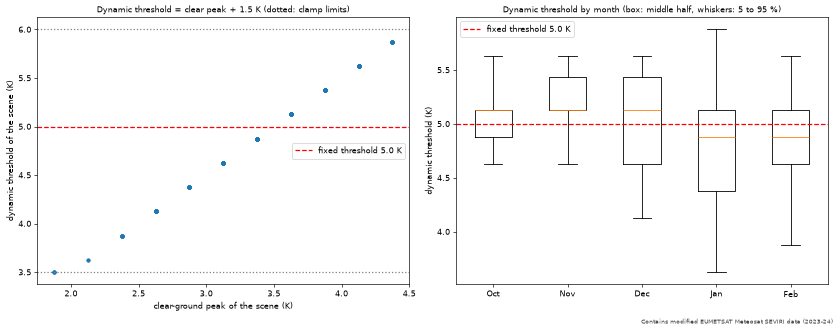

In [24]:
fig, (scatter_ax, month_ax) = plt.subplots(1, 2, figsize=(14, 5.5))

scatter_ax.scatter(dynamic_scenes["clear_peak"], dynamic_scenes["threshold"], s=14)
scatter_ax.axhline(
    params.btd_fixed, color="red", linestyle="--", label=f"fixed threshold {params.btd_fixed} K"
)
for limit in dynamic_params.clamp:
    scatter_ax.axhline(limit, color="0.5", linestyle=":")
scatter_ax.set_xlabel("clear-ground peak of the scene (K)")
scatter_ax.set_ylabel("dynamic threshold of the scene (K)")
scatter_ax.set_title("Dynamic threshold = clear peak + 1.5 K (dotted: clamp limits)", fontsize=10)
scatter_ax.legend()

by_month = [dynamic_scenes.loc[dynamic_scenes["month"] == month, "threshold"] for month in SEASON_MONTHS]
month_ax.boxplot(by_month, whis=(5, 95), showfliers=False)
month_ax.set_xticks(range(1, len(MONTH_NAMES) + 1), MONTH_NAMES)
month_ax.axhline(params.btd_fixed, color="red", linestyle="--", label=f"fixed threshold {params.btd_fixed} K")
month_ax.set_ylabel("dynamic threshold (K)")
month_ax.set_title("Dynamic threshold by month (box: middle half, whiskers: 5 to 95 %)", fontsize=10)
month_ax.legend()
save_figure(fig, "dynamic_threshold_check.png")

## What the exploration found

| Question | Measurement (2023-24, 304 night scenes) | Value for the labels |
|---|---|---|
| Where does clear ground sit? | Median **3.6 K**, middle half 3.1 to 3.9 K, extremes 1.9 and 5.1 K. Not at 0 K. | `clear_window` 1.5 to 4.75 K (covers the 1st to 99th percentile of the scene peaks) |
| Does it drift with the viewing angle? | Yes: about **+1 K** from 54° to 65° (+0.06 K per degree), mixed with latitude. | No correction for now; the check scenes decide |
| Month, time of night? | Little: medians within 0.25 K of each other. | none |
| Where does low cloud sit? | About 5 to 8 K. Where there are two humps, the low-cloud peak is about 2.6 K above the clear peak, and the valley between them is 1.5 K above it. | fixed threshold `btd_fixed` **5.0 K** (median clear peak 3.6 K plus 1.5 K); dynamic `offset` **1.5 K** |
| How cold are low-cloud tops? | 1 % of the low-cloud pixels are colder than 249 to 256 K in November to January; 260 K would remove 14 % of them in November and December. | `warm_min_bt108` **255 K** (removes at most 2 % in any month) |
| Split window of low cloud against thin cirrus? | Low cloud: median 0.2 K, 99 % below 1.2 K. Thin cirrus: median 2.9 K, 5 % below 1.9 K. The two errors are equal at 1.2 K. | `cirrus_max_split` **1.5 K** (0.2 % of low cloud removed, 2.1 % of cirrus kept) |
| Are there two humps? | Only in **41 of 303** scenes (mostly January and February), and the valley is shallow (depth 0.78 on average). | the valley method was dropped |
| What does the dynamic threshold do? | The valley idea found a valley in **0 of 304** scenes. The peak-plus-offset idea: see the counts in section 5 above. | `offset` 1.5 K, `clamp` 3.5 to 6.0 K, `min_pixels` 2000 |

The values are written down with their reasons in `docs/notes/btd_exploration.md` and set in `configs/default.yaml`.